# Oxfordshire house prices dashboard

In [369]:
import sys
print(sys.executable)
print(sys.prefix)

c:\Users\Tom\Exercism\python\Week_12_dashboards\.venv\Scripts\python.exe
c:\Users\Tom\Exercism\python\Week_12_dashboards\.venv


In [370]:
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt



In [371]:
loaded = pd.read_parquet('data/pp_epc_oxfordshire_2015_2025_v2.parquet')

print(loaded.shape)
print(loaded.dtypes)

(114424, 44)
unique_id                                 str
price_paid                              int64
deed_date                      datetime64[ns]
address                                   str
saon                                      str
paon                                      str
street                                    str
locality                                  str
town                                      str
district                                  str
postcode                                  str
property_subtype                          str
new_build                                 str
estate_type                               str
transaction_category                      str
certificate_number                        str
built_form                                str
construction_age_band                     str
current_energy_efficiency               int64
current_energy_rating                     str
energy_consumption_current            float64
extension_count      

### Questions
- For a property investor
    - How does £ per sqm floor_area vary between districts? Where is space cheapest?
    - Do homes with poor energy efficiency sell at a discount (per m2)?
        - Landlords have to meet a minimum energy rating to let, which may be raised
    - Do prices or sales volume vary throughout the year? When are they lowest/highest?
        - Compare months within a year to avoid long term price rise trend
    - Do new builds cost more per m2?
    - What has been the overall price/volume trend since 2015?
        - Did sales volumes or prices change when tax changes took place?
            - Extra stamp duty changes (first in April 2016 for additional properties then increased)

In [372]:
loaded['transaction_category'].value_counts()

transaction_category
A    105046
B      9378
Name: count, dtype: int64

year
2015    0.047802
2016    0.063367
2017    0.079416
2018    0.089947
2019    0.099197
2020    0.078537
2021    0.079758
2022    0.081721
2023    0.101753
2024    0.100585
2025    0.081928
Name: share_b, dtype: float64


<Axes: xlabel='year', ylabel='share_b'>

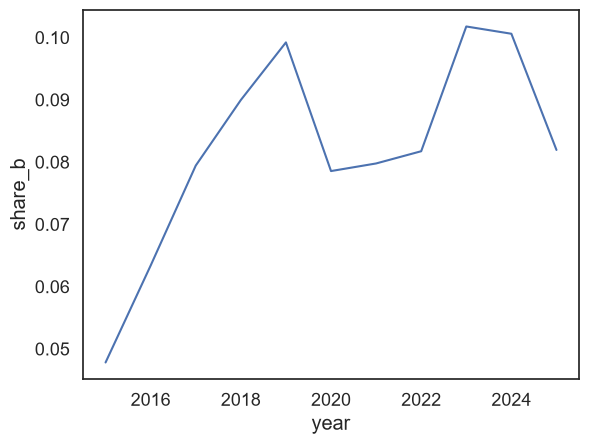

In [373]:
loaded['share_b'] = (loaded['transaction_category'] == 'B')
share_b_table = loaded.groupby('year')['share_b'].mean()
print(share_b_table)
sns.lineplot(share_b_table)


In [374]:
pd.crosstab(loaded['year'], loaded['transaction_category'], normalize='index')

transaction_category,A,B
year,,
2015,0.952198,0.047802
2016,0.936633,0.063367
2017,0.920584,0.079416
2018,0.910053,0.089947
2019,0.900803,0.099197
2020,0.921463,0.078537
2021,0.920242,0.079758
2022,0.918279,0.081721
2023,0.898247,0.101753


     year  month  unique_id
120  2025      1        765
121  2025      2        819
122  2025      3       1617
123  2025      4        357
124  2025      5        649
125  2025      6        926
126  2025      7        863
127  2025      8        953
128  2025      9        856
129  2025     10        872
130  2025     11        727
131  2025     12        678


<Axes: xlabel='month', ylabel='unique_id'>

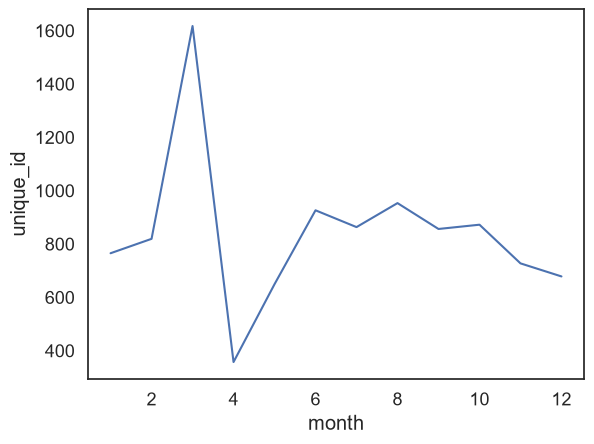

In [375]:
monthly_vol = pd.DataFrame(loaded.groupby(['year', 'month'])['unique_id'].count()).reset_index()
print(monthly_vol[monthly_vol['year'] == 2025])
sns.lineplot(monthly_vol[monthly_vol['year'] == 2025], x = 'month', y='unique_id')

# Faceting exercise (Day 1)

In [376]:
cat_a_only = loaded[loaded['transaction_category'] == 'A'].copy()
cat_a_only.shape

(105046, 45)

<Axes: xlabel='£/m2', ylabel='property_subtype'>

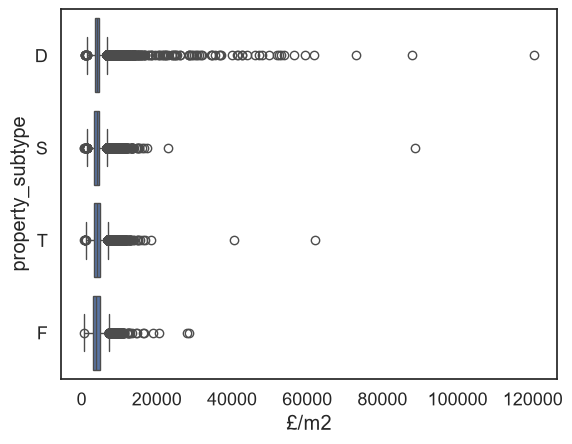

In [377]:
cat_a_only['£/m2'] = cat_a_only['price_paid'] / cat_a_only['total_floor_area']
sns.boxplot(cat_a_only, x='£/m2', y='property_subtype')


- O (Other) property_subtype no present in the data

In [378]:
labels = {'F': 'Flat', 'T': 'Terraced', 'S': 'Semi-detached', 'D': 'Detached'}

cat_a_only['property_subtype'] = cat_a_only['property_subtype'].replace(labels)

In [379]:
recent_years = cat_a_only[cat_a_only['year'].isin([2023, 2024, 2025])]
recent_years.groupby(['property_subtype', 'district'])['unique_id'].count()

property_subtype  district           
Detached          CHERWELL               1939
                  OXFORD                  339
                  SOUTH OXFORDSHIRE      2142
                  VALE OF WHITE HORSE    2419
                  WEST OXFORDSHIRE       1348
Flat              CHERWELL                619
                  OXFORD                  795
                  SOUTH OXFORDSHIRE       732
                  VALE OF WHITE HORSE     769
                  WEST OXFORDSHIRE        553
Semi-detached     CHERWELL               1929
                  OXFORD                 1096
                  SOUTH OXFORDSHIRE      1951
                  VALE OF WHITE HORSE    1873
                  WEST OXFORDSHIRE       1229
Terraced          CHERWELL               1618
                  OXFORD                 1167
                  SOUTH OXFORDSHIRE      1309
                  VALE OF WHITE HORSE    1260
                  WEST OXFORDSHIRE       1027
Name: unique_id, dtype: int64

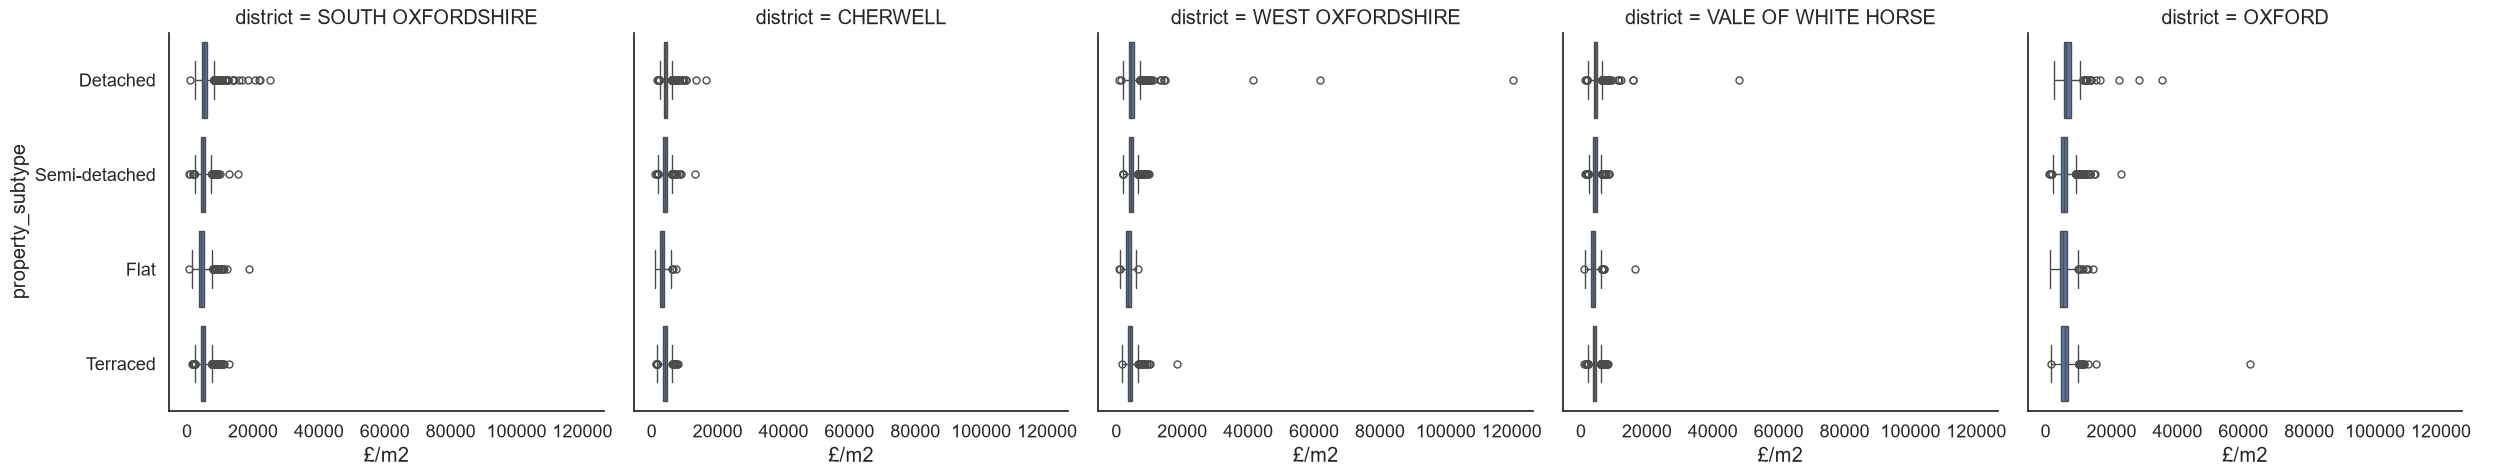

In [380]:
g = sns.catplot(recent_years, x= '£/m2', y='property_subtype', col='district', kind='box')
# g.set(xlim=(0, 40000))

In [381]:
cat_a_only[cat_a_only['£/m2'] > 25000][['unique_id', 'address', 'price_paid', 'total_floor_area', 'number_habitable_rooms', 'property_subtype', '£/m2']].sort_values(by='£/m2', ascending=False)

,unique_id,address,price_paid,total_floor_area,number_habitable_rooms,property_subtype,£/m2
104391,38EDC0C3-3B52-0F63-E063-4704A8C00424,NEW GARDENS COTTAGE LEDWELL ROAD GREAT TEW OX7...,16500000,137.0,5.0,Detached,120437.956204
80842,F87E72F9-526D-176C-E053-6B04A8C0D2BE,10 STRATFIELD ROAD OX2 7BQ,1595000,18.0,1.0,Semi-detached,88611.111111
112426,EA3278AA-5AAE-2676-E053-6B04A8C015F8,YEW TREE HOUSE LONGWORTH OX13 5EP,3250000,37.0,1.0,Detached,87837.837838
107269,EA3278AA-5D10-2676-E053-6B04A8C015F8,JORDLEYS MANOR ROAD GORING RG8 9EN,1900000,26.0,1.0,Detached,73076.923077
92194,2F7F2B43-5A4B-E08F-E063-4804A8C05A49,10 KINGSTON ROAD OX2 6EF,1055000,17.0,1.0,Terraced,62058.823529
42452,42C129E4-F972-60A9-E063-4804A8C0C25D,LINCOLN FARMHOUSE HIGH STREET STANDLAKE OX29 7RH,1420000,23.0,2.0,Detached,61739.130435
95033,726BF13B-27FD-0A46-E053-6C04A8C01D0D,YEW TREE HOUSE LONGWORTH OX13 5EP,2200000,37.0,1.0,Detached,59459.459459
42755,A96E4ACC-724F-9205-E053-6C04A8C0DA09,COTTONSTONES MILL ROAD SHIPLAKE RG9 3LT,2425000,43.0,1.0,Detached,56395.348837
73817,B0A9D11B-B3FD-4C1F-E053-6C04A8C0D716,THE MILL COTTAGE LOCK APPROACH GORING RG8 9AD,3878250,72.0,1.0,Detached,53864.583333
97373,C74B2393-1C6C-4751-89F0-F519A836CACB,ORCHARD LEA PLAYHATCH RG4 9QU,1325000,25.0,1.0,Detached,53000.000000


In [382]:
sorted_medians = recent_years.groupby('district')['£/m2'].median().sort_values()
sorted_idx = list(sorted_medians.index)
print(sorted_idx)

['CHERWELL', 'VALE OF WHITE HORSE', 'WEST OXFORDSHIRE', 'SOUTH OXFORDSHIRE', 'OXFORD']


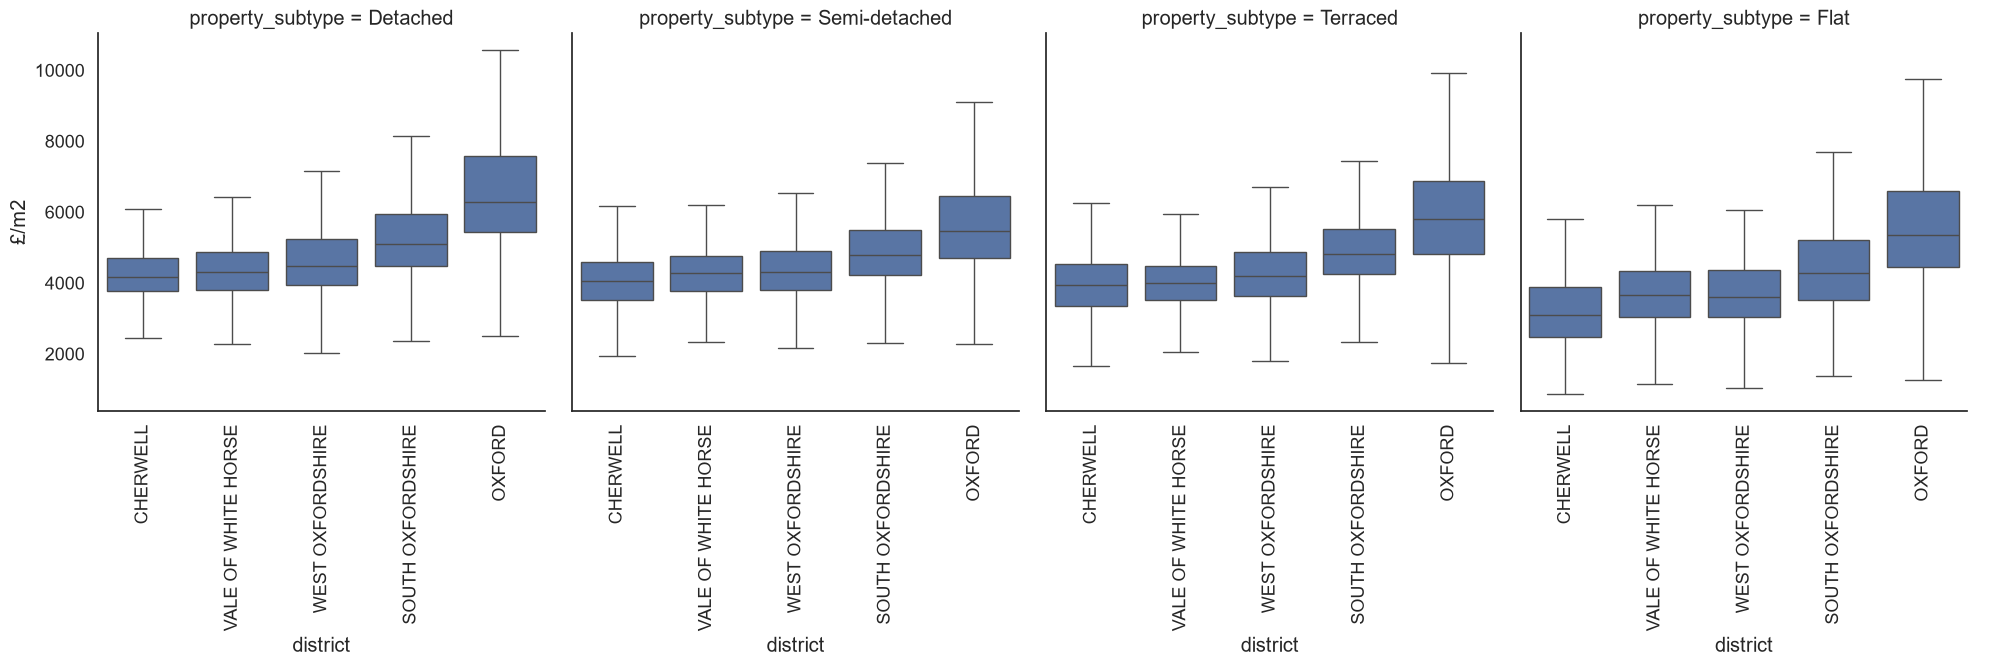

In [383]:
col_order = ['Detached', 'Semi-detached', 'Terraced', 'Flat']
g = sns.catplot(recent_years, y= '£/m2', col='property_subtype', x='district', kind='box', showfliers=False, order= sorted_idx, col_order=col_order)
g.set_xticklabels(rotation=90)


- Outliers not shown
- Panels share a similar range on y-axis, so no reason to use independent axes. Shared axis helps make accurate comparisons between panels

In [384]:
pd.concat([recent_years.groupby(['property_subtype', 'district'])['£/m2'].median(), recent_years[recent_years['£/m2'] < 20000].groupby(['property_subtype', 'district'])['£/m2'].median()], axis=1, keys=['all £/m2', '<20000 £/m2'])

all £/m2  <20000 £/m2
property_subtype district                                     
Detached         CHERWELL             4175.824176  4175.824176
                 OXFORD               6285.714286  6256.578947
                 SOUTH OXFORDSHIRE    5107.526882  5107.334869
                 VALE OF WHITE HORSE  4312.796209  4312.648104
                 WEST OXFORDSHIRE     4466.185410  4464.285714
Flat             CHERWELL             3096.491228  3096.491228
                 OXFORD               5343.137255  5343.137255
                 SOUTH OXFORDSHIRE    4271.428571  4271.428571
                 VALE OF WHITE HORSE  3648.148148  3648.148148
                 WEST OXFORDSHIRE     3615.384615  3615.384615
Semi-detached    CHERWELL             4045.801527  4045.801527
                 OXFORD               5475.321515  5474.452555
                 SOUTH OXFORDSHIRE    4800.000000  4800.000000
                 VALE OF WHITE HORSE  4278.350515  4278.350515
                 WEST OXFORDSHIRE     4302.325581  4302.325581
Terraced         CHERWELL             3926.150483  3926.150483
                 OXFORD               5798.611111  5796.130952
                 SOUTH OXFORDSHIRE    4807.692308  4807.692308
                 VALE OF WHITE HORSE  3986.100386  3986.100386
                 WEST OXFORDSHIRE     4207.317073  4207.317073

- Excluding £/m2 > 20,000 does not meaningfully change the median values

# Data-to-ink and visual hierarchy (Day 2)

### Chart 1

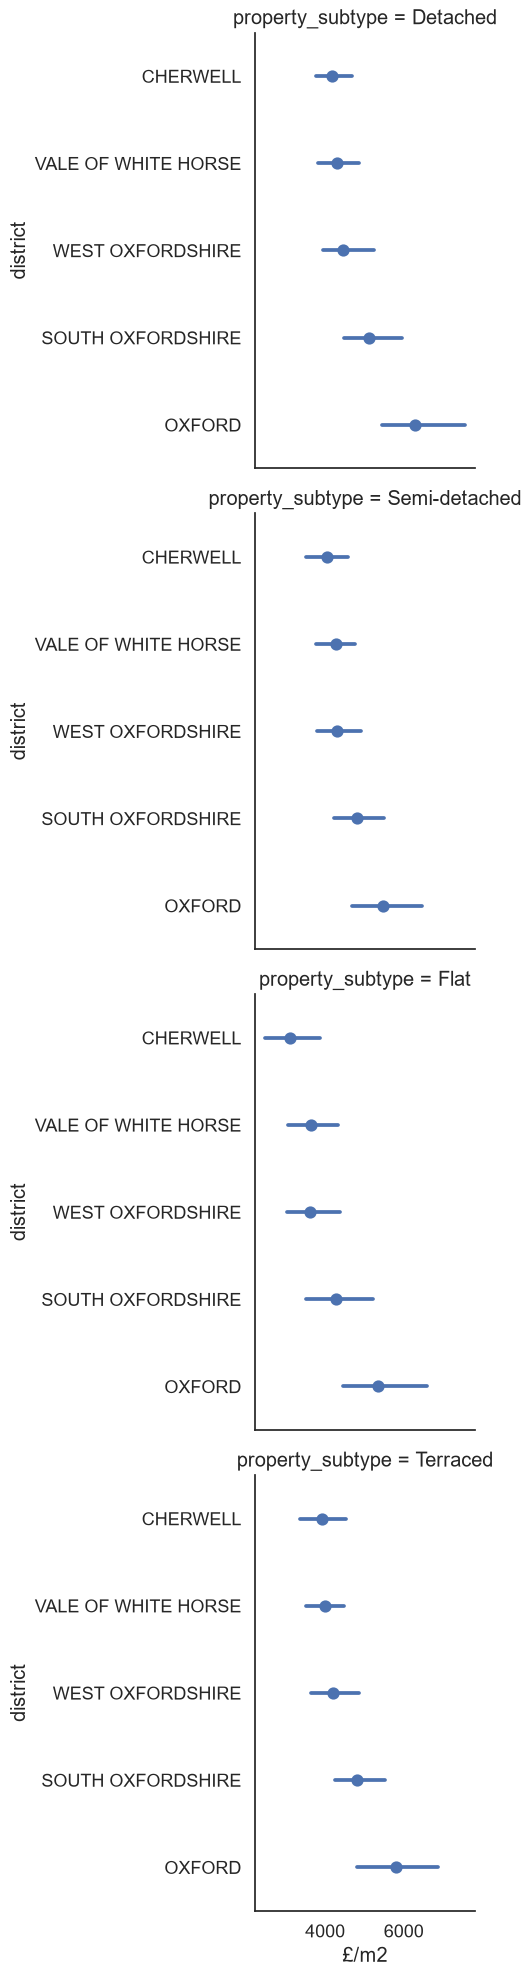

In [385]:
col_order = ['Detached', 'Semi-detached', 'Terraced', 'Flat']
g = sns.catplot(recent_years, x= '£/m2', row='property_subtype', y='district', kind='point', order= sorted_idx, col_order=col_order, estimator='median', linestyle='none', errorbar=('pi', 50))
# g.set_xticklabels(rotation=90)



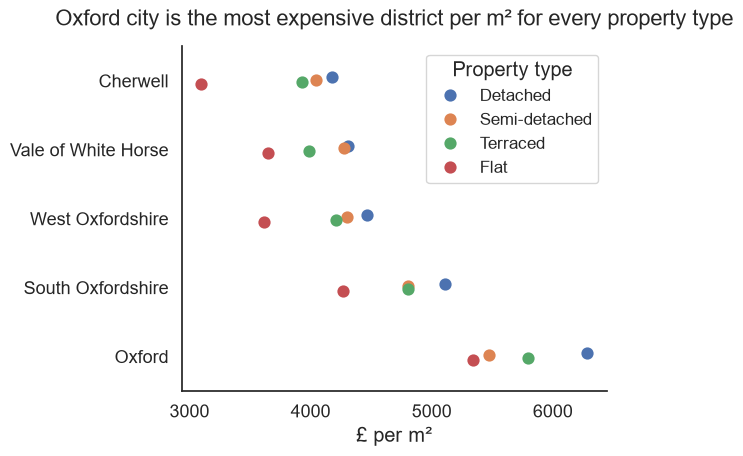

In [386]:
recent_years['district'] = recent_years['district'].str.title().str.replace('Of', 'of')
sorted_medians = recent_years.groupby('district')['£/m2'].median().sort_values()
sorted_idx = list(sorted_medians.index)

sns.set_theme(style='white', font_scale=1.2)
g= sns.pointplot(recent_years, x= '£/m2', hue='property_subtype', y='district', order=sorted_idx, hue_order=['Detached', 'Semi-detached', 'Terraced', 'Flat'], dodge=True, estimator='median', linestyle='none', errorbar=None)
g.set_title('Oxford city is the most expensive district per m² for every property type', pad=15, fontsize=16)
g.set(ylabel='', xlabel='£ per m²')
g.legend(title='Property type', fontsize=12)
sns.despine()
plt.tight_layout()
plt.show()

- The finding: Oxford city costs 50% more per m2 than Cherwell for every property type

### Chart 2

- What has been the overall price/volume trend since 2015?
    - Did sales volumes or prices change when tax changes took place?
        - Extra stamp duty changes (first in April 2016 for additional properties then increased)

     year  month  unique_id
0    2015      1        553
1    2015      2        547
2    2015      3        662
3    2015      4        617
4    2015      5        741
..    ...    ...        ...
127  2025      8        888
128  2025      9        793
129  2025     10        813
130  2025     11        662
131  2025     12        602

[132 rows x 3 columns]


<Axes: xlabel='month', ylabel='unique_id'>

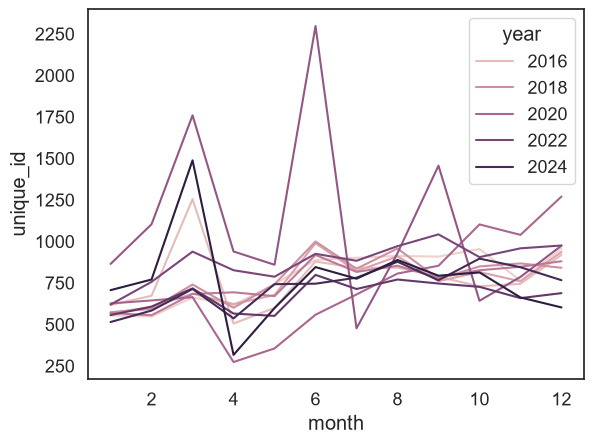

In [387]:
monthly_volume = cat_a_only.groupby(['year', 'month'])['unique_id'].count().reset_index()
print(monthly_volume)
sns.lineplot(monthly_volume, x='month', y='unique_id', hue='year')

#### Before

    year_month  unique_id
0       2015-1        553
1      2015-10        954
2      2015-11        763
3      2015-12        956
4       2015-2        547
..         ...        ...
127     2025-5        598
128     2025-6        845
129     2025-7        775
130     2025-8        888
131     2025-9        793

[132 rows x 2 columns]


<Axes: xlabel='year_month', ylabel='unique_id'>

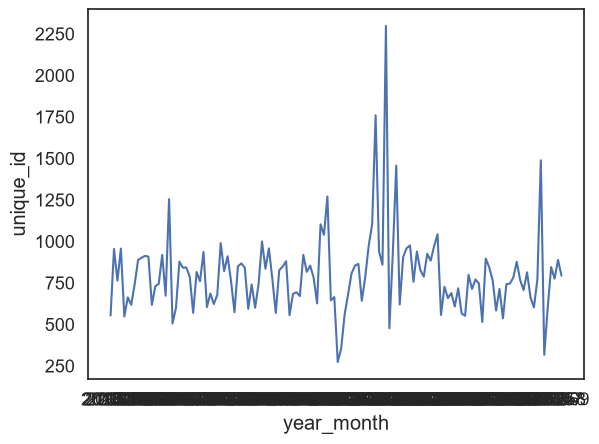

In [388]:
cat_a_only['year_month'] = cat_a_only['year'].astype(str) + '-' + cat_a_only['month'].astype(str)
cat_a_only['year_month'].value_counts()

year_monthly_volume = cat_a_only.groupby(['year_month'])['unique_id'].count().reset_index()
print(year_monthly_volume)
sns.lineplot(year_monthly_volume, x='year_month', y='unique_id')

#### After

deed_date
2015-01-01    553
2015-02-01    547
2015-03-01    662
2015-04-01    617
2015-05-01    741
             ... 
2025-08-01    888
2025-09-01    793
2025-10-01    813
2025-11-01    662
2025-12-01    602
Freq: MS, Name: unique_id, Length: 132, dtype: int64


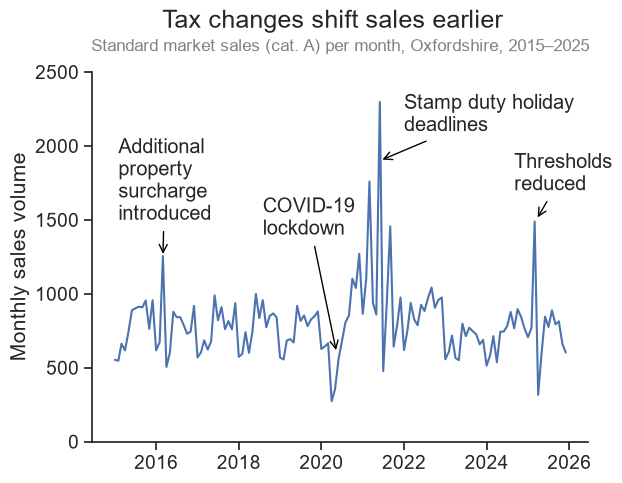

In [389]:
year_monthly_volume = cat_a_only.resample('MS', on='deed_date')['unique_id'].count()
print(year_monthly_volume)
# sns.set_theme(style='white')
g = sns.lineplot(year_monthly_volume)
g.set(xlabel=None)
g.figure.suptitle('Tax changes shift sales earlier', fontsize=18, y=1.01)
g.set_title('Standard market sales (cat. A) per month, Oxfordshire, 2015–2025', fontsize=12, color='grey', pad=15)
g.set_ylabel('Monthly sales volume', fontsize=15)
g.set_ylim(ymin=0, ymax=2500)
g.tick_params(axis='both', labelsize=14, bottom=True, left=True)
g.annotate('Additional\nproperty\nsurcharge\nintroduced', xy=(pd.Timestamp('2016-03-01'), 1250), xytext=(pd.Timestamp('2015-02-01'), 1500), arrowprops=dict(arrowstyle='->', color='black'))
g.annotate('COVID-19\nlockdown', xy=(pd.Timestamp('2020-05-15'), 600), xytext=(pd.Timestamp('2018-08-01'), 1400), arrowprops=dict(arrowstyle='->', color='black'))
g.annotate('Stamp duty holiday\ndeadlines', xy=(pd.Timestamp('2021-06-01'), 1900), xytext=(pd.Timestamp('2022-01-01'), 2100), arrowprops=dict(arrowstyle='->', color='black'))
g.annotate('Thresholds\nreduced', xy=(pd.Timestamp('2025-03-15'), 1500), xytext=(pd.Timestamp('2024-09-01'), 1700), arrowprops=dict(arrowstyle='->', color='black'))
sns.despine()
# plt.tight_layout()
plt.show()


#### For Q3

     year  month  unique_id
0    2015      1        553
1    2015      2        547
2    2015      3        662
3    2015      4        617
4    2015      5        741
..    ...    ...        ...
127  2025      8        888
128  2025      9        793
129  2025     10        813
130  2025     11        662
131  2025     12        602

[132 rows x 3 columns]


<Axes: xlabel='month', ylabel='unique_id'>

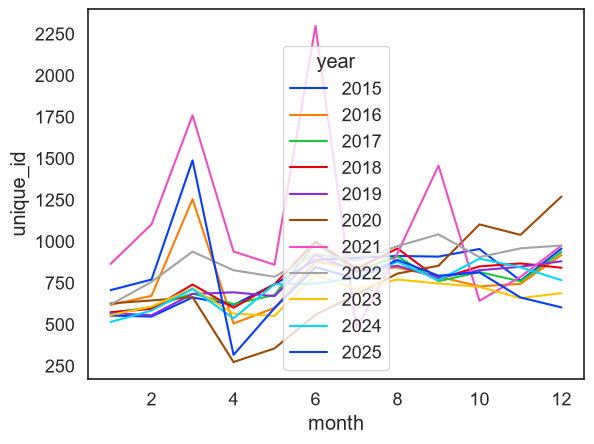

In [390]:
monthly_volume = cat_a_only.groupby(['year', 'month'])['unique_id'].count().reset_index()
print(monthly_volume)
sns.lineplot(monthly_volume, x='month', y='unique_id', hue='year', palette='bright')

In [391]:
import plotly.express as px

In [410]:
recent_years_agg= recent_years.groupby(['district', 'property_subtype'])['£/m2'].agg(['median', 'count']).reset_index()
fig = px.scatter(recent_years_agg, 
           x= 'median', 
           y='district', 
           color='property_subtype', 
           color_discrete_map={'Detached':'blue', 'Semi-detatched':'orange', 'Terraced':'green', 'Flat':'red'}, 
           category_orders={'district':['Cherwell', 'Vale of White Horse', 'West Oxfordshire', 'South Oxfordshire', 'Oxford']},
           template='plotly_white')
fig.update_xaxes(title_text='£ per m²')
fig.update_yaxes(title_text=None)
fig.update_layout({'title':{'text':'Oxford city is the most expensive district per m² for every property type'}, 'legend_title_text':"Property Type", })



# color_discrete_map={'Detatched':'blue', 'Semi-detatched':'yellow', 'Terraced':'yellow', 'Flat':'red'})
# sns.set_theme(style='white', font_scale=1.2)
# g= sns.pointplot(recent_years, x= '£/m2', hue='property_subtype', y='district', order=sorted_idx, hue_order=['Detached', 'Semi-detached', 'Terraced', 'Flat'], dodge=True, estimator='median', linestyle='none', errorbar=None)
# g.set_title('Oxford city is the most expensive district per m² for every property type', pad=15, fontsize=16)
# g.set(ylabel='', xlabel='£ per m²')
# g.legend(title='Property type', fontsize=12)
